# ПЗ-8. Автоматическое дифференцирование: дуалы, ленты и настоящие градиенты
### (репетиция Лекции 8 — прямой режим, обратный режим, JVP/VJP, PyTorch)

> Разности (Л6) платят точностью, комплексный
> шаг (Л7) — аналитичностью и прогонами. Автодифференцирование берёт
> **код как есть** и выносит из него градиент с точностью до машинного
> эпсилон за цену нескольких проходов. Сегодня мы соберём оба режима
> руками и погоняем настоящий `autograd` на живых задачах.

| уровень | метка | что это значит |
|---|---|---|
| 🟢 | прогрев | детский сад |
| 🟠 | продвинутая | базовый минимум |
| ★ | звёздочка | альфа |
| ★★ | двойная звёздочка | сигма |

**Как работать.** Постановки — в md-блоках, решаете — в ячейках
`✍️ ДЕЛАЙТЕ`. Проверка `✅` исполняется без ошибок только при
верном решении. Идите сверху вниз. На задачах 1 и 4–8 пригодится
`torch`; задачи 2–3 — чистый Python без torch.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch
plt.rcParams['figure.dpi'] = 110
torch.manual_seed(0)
print('numpy', np.__version__, '| torch', torch.__version__)

numpy 2.5.4 | torch 2.11.0+cpu


## 📋 Шпаргалка

**AD за пять строк.** Программа = граф примитивов с локальными
производными. Прямой режим тащит **касательные**
$\tilde v_i = \sum_j \frac{\partial\varphi_i}{\partial v_j}\tilde v_{i_j}$
(на выходе — столбец якобиана $J\,e_j$); обратный — **сопряжённые**
$\bar v_j \,{+}{=}\, \bar v_i\,\frac{\partial v_i}{\partial v_j}$
от seed $\bar y = 1$ (на выходе — строка $u^{\top}J$).

| инструмент | что делает | где |
|---|---|---|
| дуальные числа $a + b\,\varepsilon$, $\varepsilon^2 = 0$ | прямой режим одной оценкой: `val, dval` | Задача 2 |
| лента + `+=` накопление | обратный режим одним backward | Задача 3 |
| `torch.autograd.grad / backward` | обратный режим на тензорах | Задачи 1, 4, 7 |
| `torch.func.jvp` / `torch.func.vjp` | JVP и VJP с seed-вектором | Задача 5 |
| `torch.func.jacfwd` / `jacrev` | полный якобиан прямым/обратным | Задача 6 |
| `torch.utils.checkpoint` | память $O(\sqrt L)$ ценой +1 forward | Задача 8 |

**Сложность (Баура–Штрассен, 1983).** Градиент любой арифметической
программы за $\sim\!2$–$3$ прохода той же программы (по времени),
но прямой режим платит прогонами на **направление** ($n$ штук),
а обратный — памятью на **ленту** ($O(L)$).

**Честность.** AD дифференцирует реализацию: негладкие точки
(`relu`, `abs`, `max`) получают конвенциональное значение
(gradcheck никогда не сойдётся там, где производной нет);
устойчивость формул яснее проверять до дифференцирования.

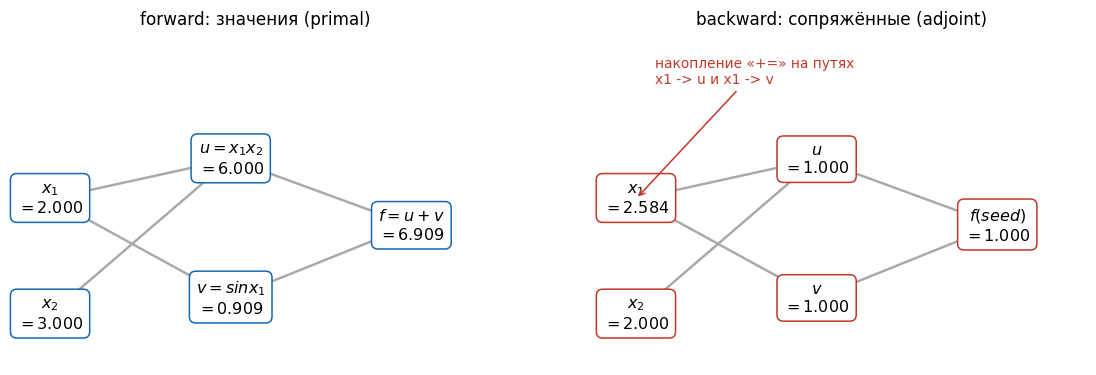

In [2]:
# Карта примера Лекции 8: f = x1*x2 + sin(x1) — значения вперёд, сопряжённые назад
fig, axes = plt.subplots(1, 2, figsize=(12.6, 3.9))
POS = {"x1": (0.08, 0.5), "x2": (0.08, 0.15), "u": (0.45, 0.62),
       "v": (0.45, 0.2), "f": (0.82, 0.42)}
EDGES = [("x1", "u"), ("x2", "u"), ("x1", "v"), ("u", "f"), ("v", "f")]
NODES_F = [("x1", "x_1", 2.0), ("x2", "x_2", 3.0), ("u", "u = x_1 x_2", 6.0),
           ("v", "v = sin x_1", np.sin(2.0)), ("f", "f = u + v", 6.0 + np.sin(2.0))]
NODES_B = [("x1", "x_1", 3.0 + np.cos(2.0)), ("x2", "x_2", 2.0),
           ("u", "u", 1.0), ("v", "v", 1.0), ("f", "f (seed)", 1.0)]
for ax, nodes, ttl, col in [(axes[0], NODES_F, "forward: значения (primal)", "#1667b3"),
                            (axes[1], NODES_B, "backward: сопряжённые (adjoint)", "#c0392b")]:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    for a, b in EDGES:
        # в forward стрелка идёт от входа к выходу, в backward — наоборот
        tail, head = (POS[a], POS[b]) if ttl.startswith("forward") else (POS[b], POS[a])
        ax.annotate('', xy=head, xytext=tail,
                    arrowprops=dict(arrowstyle='->', color='darkgray', lw=1.6))
    for nid, label, val in nodes:
        px, py = POS[nid]
        ax.text(px, py, f"${label}$\n$= {val:.3f}$", ha="center", va="center",
                fontsize=10.5, bbox=dict(boxstyle="round,pad=0.4",
                                         fc="white", ec=col))
    ax.set_title(ttl, fontsize=11)
axes[1].annotate("накопление «+=» на путях\nx1 -> u и x1 -> v",
                 xy=(0.08, 0.5), xytext=(0.12, 0.85),
                 arrowprops=dict(arrowstyle="->", color="#c0392b"),
                 fontsize=9, color="#c0392b")
plt.show()

---
## 🟢 Задача 1. Первый градиент: ноль шагов $h$

$$f(x) = \sin x + x^{2}, \qquad x_0 = 1.$$

**Что сделать:**

- **(а)** Вычислить $f'(x_0)$ через `loss.backward()` и собрать `G1`
  (значение — `x.grad[0].item()`).
- **(б)** Не обнуляя `x.grad`, построить и прогнать потерю ещё раз —
  собрать `G2`. Объяснить, что произошло
  (накопление «${+}{=}$» в узле `AccumulateGrad`).
- **(в)** Обнулить (`x.grad = None` — то же, что `optimizer.zero_grad()`)
  и собрать `G3`. Сверить все три с аналитическим решением $\cos 1 + 2$.


In [3]:
# Каркас задачи 1: функция и точное значение
FP = lambda xt: torch.sin(xt) + xt ** 2
G_EXACT = float(np.cos(1.0) + 2.0)
print(f"f = sin(x) + x^2,  x0 = 1,  точная f' = cos(1) + 2 = {G_EXACT:.12f}")
print("контракты: G1 — после 1-го backward; G2 — после 2-го БЕЗ обнуления;")
print("           G3 — после zero_grad и 3-го backward. Все — числа типа float")

f = sin(x) + x^2,  x0 = 1,  точная f' = cos(1) + 2 = 2.540302305868
контракты: G1 — после 1-го backward; G2 — после 2-го БЕЗ обнуления;
           G3 — после zero_grad и 3-го backward. Все — числа типа float


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 1
# TODO (а): G1 — производная одним backward (double!)
# TODO (б): G2 — второй backward без обнуления + строка-объяснение (print)
# TODO (в): G3 — zero_grad + третий backward


In [ ]:
# ✅ Самопроверка задачи 1
import numpy as np
assert abs(G1 - G_EXACT) < 1e-9, f"G1 обязан совпасть с аналитикой: {G1!r}"
assert abs(G2 - 2 * G_EXACT) < 1e-9, (f"G2 = накопленные градиенты: "
                                      f"{G2!r} ≠ 2×({G_EXACT:.6f})")
assert abs(G3 - G_EXACT) < 1e-9, f"G3 после обнуления обязан совпасть: {G3!r}"
print(f"✅ Задача 1 ок: G1 = {G1:.12f}; G2 = {G2:.12f} (накопление «+=»); "
      f"G3 = {G3:.12f}")

## 🟠 Задача 2. Дуальные числа: дописать арифметику и продифференцировать функции

### Контекст

Дуальное число — это пара $(a, \tilde a)$, где $a$ — значение, а $\tilde a$ — производная.
Оно ведёт себя как $a + \tilde a\,\varepsilon$ при $\varepsilon^2 = 0$. Арифметика на таких
парах автоматически даёт производные через правила дифференцирования.

Вам дан каркас класса `Dual` (из Лекции 8), в котором уже реализованы:

- `__init__`, `val`, `dval`;
- `__add__`, `__mul__`;
- `__sub__` — как образец того, как оформлять операции.

### Что нужно сделать

**(а) Дописать операции и функции.**
Используя правила дифференцирования:

- частное $c = a/b$:

$$
c_{\text{val}} = \frac{a_{\text{val}}}{b_{\text{val}}},
\qquad
c_{\text{dval}} = \frac{a_{\text{dval}}\,b_{\text{val}} - a_{\text{val}}\,b_{\text{dval}}}{b_{\text{val}}^2}.
$$

- степень $c = x^p$ (при постоянном вещественном $p$):

$$
c_{\text{val}} = x_{\text{val}}^{\,p},
\qquad
c_{\text{dval}} = p\,x_{\text{val}}^{\,p-1}\,x_{\text{dval}}.
$$

- экспонента $u \mapsto e^{u}$:

$$
\big(e^{u}\big)_{\text{val}} = e^{u_{\text{val}}},
\qquad
\big(e^{u}\big)_{\text{dval}} = e^{u_{\text{val}}}\,u_{\text{dval}}.
$$

- гиперболический тангенс $u \mapsto \tanh u$:

$$
\big(\tanh u\big)_{\text{val}} = \tanh u_{\text{val}},
\qquad
\big(\tanh u\big)_{\text{dval}} = \operatorname{sech}^2(u_{\text{val}})\cdot u_{\text{dval}},
$$

где $\operatorname{sech}^2 t = 1 - \tanh^2 t$.

Реализовать:

- `Dual.__truediv__` (и, для полноты, `__rtruediv__`);
- `Dual.__pow__` (для вещественного показателя);
- `d_exp(u) -> Dual`;
- `d_tanh(u) -> Dual`.

**(б) Реализовать три функции от `Dual`:**

$$
g_1(x) = \frac{x^{2} + 1}{x + 2},
\qquad
g_2(x) = x\,e^{x}\,\tanh x,
\qquad
g_3(x) = (\tanh x + 2)^{3}.
$$

Внутри использовать только операции `Dual` и `d_exp` / `d_tanh` — никаких ручных
формул для производной.

**(в) Проверка.**
Для каждой функции взять вход `Dual(x0, 1.0)` со своим $x_0$:

| функция | $x_0$ |
|---------|-------|
| $g_1$   | 1.1   |
| $g_2$   | 0.7   |
| $g_3$   | 0.5   |

Для каждого случая напечатать и сравнить:

1. **Результат через `Dual`**: `val` и `dval`, полученные вызовом
   $g_i(\text{Dual}(x_0, 1.0))$.
2. **Точные значения**: $g_i(x_0)$ и аналитическая производная $g_i'(x_0)$,
   посчитанные «руками» по формулам.
3. **Центральная разность**:

$$
g_i'(x_0) \approx \frac{g_i(x_0 + h) - g_i(x_0 - h)}{2h},
\qquad h = 10^{-6}.
$$

Вывести расхождения `|dval - exact|` и `|dval - central_diff|`.
Ожидается: `dval` совпадает с точной производной до машинной точности,
а с центральной разностью — до $\sim 10^{-9}$–$10^{-10}$.

In [7]:
# Каркас задачи 2: Dual c готовой арифметикой
import math

class Dual:
    # дуальное число: значение + касательная
    def __init__(self, val, dval=0.0):
        self.val, self.dval = val, dval
    def __add__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.val + o.val, self.dval + o.dval)
    __radd__ = __add__
    def __mul__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.val * o.val, self.val * o.dval + o.val * self.dval)
    __rmul__ = __mul__
    def __sub__(self, o):          # вычитание — образец готовой операции
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.val - o.val, self.dval - o.dval)
    # ↓ TODO (а): __truediv__, __pow__, d_exp(u), d_tanh(u)

X0G1, X0G2, X0G3 = 1.1, 0.7, 0.5
print("контракты: g1(x: Dual) -> Dual, g2, g3")
print(f"x0: g1 при {X0G1}, g2 при {X0G2}, g3 при {X0G3}")
print("прогон: Dual(x0, 1.0) -> y.val (значение), y.dval (производная)")

контракты: g1(x: Dual) -> Dual, g2, g3
x0: g1 при 1.1, g2 при 0.7, g3 при 0.5
прогон: Dual(x0, 1.0) -> y.val (значение), y.dval (производная)


In [8]:
# ✍️ ДЕЛАЙТЕ — Задача 2
# TODO (а): __truediv__, __pow__ (методы внутри класса), d_exp, d_tanh (функции)
# TODO (б): g1, g2, g3 — функции от Dual
# TODO (в): прогон и печать val/dval против точных значений


In [ ]:
# ✅ Самопроверка задачи 2
import numpy as np
import math
import sympy as sp
XS = sp.symbols('x')
REGS = [(g1, X0G1, (XS**2 + 1) / (XS + 2)),
        (g2, X0G2, XS * sp.exp(XS) * sp.tanh(XS)),
        (g3, X0G3, (sp.tanh(XS) + 2) ** 3)]
for i, (gfn, x0, ex) in enumerate(REGS, 1):
    y = gfn(Dual(x0, 1.0))
    ev = float(ex.subs(XS, x0))
    ed = float(sp.diff(ex, XS).subs(XS, x0))
    h = 1e-5
    realk = lambda t: float(ex.subs(XS, t))
    cd = (realk(x0 + h) - realk(x0 - h)) / (2 * h)
    assert abs(y.val - ev) < 1e-10, f"g{i}.val: {y.val!r} vs {ev!r}"
    assert abs(y.dval - ed) < 1e-10, f"g{i}.dval: {y.dval!r} vs {ed!r}"
    assert abs(cd - ed) < 1e-6, f"g{i}: движок сам не согласован ({cd!r})"
print("✅ Задача 2 ок: дуальное кольцо согласуется с sympy на g1/g2/g3")

---
## 🟠 Задача 3. Обратный режим дифференцирования: дописать `Var` и посчитать $\nabla g$

### Контекст

В каркасе дан класс `Var` — узел вычислительного графа для
обратного режима автоматического дифференцирования. В нём уже реализованы:

- `__add__`, `__mul__`;
- `sin(...)` — как пример операции, регистрирующей правило для `backward`;
- `backward(...)` — топологический обход графа и накопление градиентов
  через `+=` (правило «суммируй вклады от всех потребителей»).

Каждый `Var` хранит `val` (число) и `grad` (накопленный градиент,
по умолчанию `0.0`). Операция над `Var` создаёт новый `Var` и запоминает,
как переслать градиент назад к родителям.

### Что нужно сделать

**(а) Дописать операции над `Var`.**

Используя правила дифференцирования
$$\frac{d}{dz}e^{z} = e^{z}, \qquad \frac{d}{dz}\ln z = \frac{1}{z},$$

реализовать:

- `__sub__` (при желании — ещё и `__rsub__`, чтобы работало `2 - x`);
- `exp(v)` — возвращает `Var`, значение $e^{v_{\text{val}}}$, и при
  `backward` пересылает градиент $\cdot\, e^{v_{\text{val}}}$ к `v`;
- `log(v)` — возвращает `Var`, значение $\ln v_{\text{val}}$, и при
  `backward` пересылает градиент $\cdot\, \frac{1}{v_{\text{val}}}$ к `v`.

Дописанные операции должны встраиваться в тот же механизм, что и `sin`:
никакой ручной «магии», только регистрация правила для обратного прохода.

**(б) Реализовать функцию `grad_g(xa, ya) -> (float, float)`.**

Для целевой функции
$$g(x, y) = x\,y\,e^{\,x-y} + \ln\!\bigl(x^{2} + y^{2} + 1\bigr)$$

функция должна:

1. построить `Var(xa)` и `Var(ya)`;
2. собрать выражение для $g$ из этих `Var` — только через
   `+`, `-`, `*`, `exp`, `log` (никаких заранее посчитанных формул
   для производной);
3. вызвать `backward()` от результата;
4. вернуть пару `(x.grad, y.grad)` как обычные `float`.

Ключевая идея обратного режима: **один** `backward` даёт сразу
**обе** частные производные $\partial g/\partial x$ и $\partial g/\partial y$,
потому что граф один и тот же, а градиент накапливается в каждом узле
независимо.

**(в) Проверка.**

Посчитать $\nabla g$ через `grad_g` в двух точках:

| точка | $(x, y)$ |
|---|---|
| 1 | $(1.3,\ -0.2)$ |
| 2 | $(-0.5,\ 0.7)$ |

Для каждой точки напечатать:

1. **Градиент из обратного режима**: `(gx, gy) = grad_g(x, y)` —
   оба числа из **одного** вызова `backward`.
2. **Эталон** — стандартные центральные разности по каждой переменной:

$$
\frac{\partial g}{\partial x} \approx
\frac{g(x + h,\, y) - g(x - h,\, y)}{2h},
\qquad
\frac{\partial g}{\partial y} \approx
\frac{g(x,\, y + h) - g(x,\, y - h)}{2h},
\qquad h = 10^{-6},
$$

где $g$ вычисляется «руками» через `math.exp` и `math.log`.

3. **Расхождения**: `|gx_auto - gx_num|` и `|gy_auto - gy_num|`.

Ожидается: оба компонента градиента совпадают с численными производными
до $\sim 10^{-9}$–$10^{-10}$. Если расходится — типичная причина в том,
что в `backward` забыли `+=` (перезапись вместо накопления), или что
`exp` / `log` не зарегистрировали правило пересылки градиента.

In [9]:
# Каркас задачи 3: Var с готовыми +, *, sin, backward
import math

class Var:
    # узел графа: значение + parents (узел, локальная производная) + grad
    def __init__(self, val, parents=()):
        self.val, self.parents, self.grad = val, parents, 0.0
    def __add__(self, o):
        o = o if isinstance(o, Var) else Var(o)
        return Var(self.val + o.val, ((self, 1.0), (o, 1.0)))
    def __mul__(self, o):
        o = o if isinstance(o, Var) else Var(o)
        return Var(self.val * o.val, ((self, o.val), (o, self.val)))
    def sin(self):
        return Var(math.sin(self.val), ((self, math.cos(self.val)),))
    # ↓ TODO (а): __sub__ (+ __rsub__ по желанию), exp(), log()

    def backward(self):
        # топологический порядок обхода (без рекурсии)
        order, seen = [], set()
        stack = [(self, False)]
        while stack:
            node, done = stack.pop()
            if done:
                order.append(node); continue
            if id(node) in seen:
                continue
            seen.add(id(node))
            stack.append((node, True))
            for parent, _ in node.parents:
                if id(parent) not in seen:
                    stack.append((parent, False))
        self.grad = 1.0                    # seed: сопряжённого_выхода = 1
        for node in reversed(order):       # от выхода к входам
            for parent, local in node.parents:
                parent.grad += local * node.grad    # «+=»: накапливаем!

print("контракт: grad_g(xa, ya) -> (grad_x, grad_y)")
print("проверка отладкой: g(1.3, -0.2) считается и x.grad/y.grad заполняются")

контракт: grad_g(xa, ya) -> (grad_x, grad_y)
проверка отладкой: g(1.3, -0.2) считается и x.grad/y.grad заполняются


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 3
# TODO (а): __sub__, exp(), log() внутри класса Var
# TODO (б): def grad_g(xa, ya): ... -> (x.grad, y.grad)
# TODO (в): сверка с центральными разностями в двух точках (печать)


In [ ]:
# ✅ Самопроверка задачи 3
import numpy as np
import math
def g_real(u, w):
    return u * w * math.exp(u - w) + math.log(u * u + w * w + 1.0)
def central(u, w, h=1e-5):
    gx = (g_real(u + h, w) - g_real(u - h, w)) / (2 * h)
    gy = (g_real(u, w + h) - g_real(u, w - h)) / (2 * h)
    return gx, gy
for (xa, ya) in [(1.3, -0.2), (-0.5, 0.7)]:
    gx, gy = grad_g(xa, ya)
    cx, cy = central(xa, ya)
    assert abs(gx - cx) < 1e-8, f"grad_x({xa},{ya}): {gx!r} vs {cx!r}"
    assert abs(gy - cy) < 1e-8, f"grad_y({xa},{ya}): {gy!r} vs {cy!r}"
print("✅ Задача 3 ок: лента выдаёт полный grad g за один backward")

---
## 🟠 Задача 4. Химмельблау: настоящий спуск на настоящем движке

### Контекст

Функция Химмельблау — классический тестовый пример в оптимизации:
у неё **четыре** локальных минимума с одинаковым значением $f=0$, и
область притяжения каждого устроена нетривиально.

$$
f(x, y) = \bigl(x^{2} + y - 11\bigr)^{2} + \bigl(x + y^{2} - 7\bigr)^{2}.
$$

Известные точки минимума:

$$
(3,\ 2), \quad (-2.805,\ 3.131), \quad (-3.779,\ -3.283), \quad (3.584,\ -1.848).
$$


### Что дано в каркасе

- движок дифференцирования из задачи 3 (класс `Var` с `exp`, `log`,
  `sin`, `+`, `-`, `*` и `backward`);
- функция Химмельблау, уже выраженная через `Var` (обёртка `F_H(p)`,
  где `p` — параметр-вектор длины 2);
- список `STARTS` из четырёх начальных точек;
- оптимизатор `opt` (Adam) с методами `zero_grad()` и `step()`.

Ключевая идея: `backward` сам обходит граф, ставит seed $=1$ на выход
$f$ и распространяет сопряжённые назад — итоговый градиент $\nabla f$
оказывается в `p.grad`. Ручных формул для $\partial f/\partial x$,
$\partial f/\partial y$ писать не надо.




### (а) Прогнать спуск Adam'ом из четырёх стартов

Гиперпараметры:

- learning rate: `lr = 0.05`;
- число шагов: `2000`.

Цикл на каждом шаге:

```python
opt.zero_grad()        # обнулить накопленные градиенты
F_H(p).backward()      # посчитать f и заполнить p.grad
opt.step()             # сделать шаг оптимизатора
```

Для каждого старта вывести:

1. координаты стартовой точки;
2. координаты финальной точки после 2000 шагов;
3. **расстояние до ближайшего известного корня** (евклидова норма);
4. **норму градиента** $\lVert \nabla f \rVert$ в финальной точке
   (берётся из `p.grad` сразу после последнего `backward`).

Ожидается: каждый запуск попадает в **один из четырёх** корней,
расстояние до ближайшего — порядка $10^{-4}$ и меньше,
$\lVert \nabla f \rVert$ в финале — тоже порядка $10^{-4}$ и меньше.



### (в) Контурный график + рефлексия

Построить:

- линии уровня $f(x, y)$ (`contour` по сетке
  $x \in [-5, 5]$, $y \in [-5, 5]$);
- четыре стартовые точки (маркеры);
- четыре траектории спуска (линии из последовательных $(x_t, y_t)$).

Под графиком (или в тексте ячейки) — **печатная рефлексия**:

> Почему у Adam'а нет шага $h$ «под потолок», как в обычном
> градиентном спуске (см. U-кривую из Лекции 6)?



### Технические подсказки

- `p` — это `Var` с полем `.val` (numpy-массив длины 2) и `.grad`
  той же формы. После `backward()` в `p.grad` лежит $\nabla f(p)$;
  `opt.step()` читает его и обновляет `p.val`.
- Чтобы сохранять траекторию, копируйте `p.val.copy()` на каждом шаге —
  не сохраняйте ссылку на массив, он мутируется на месте.
- `zero_grad()` **обязателен** в начале каждой итерации:
  `backward` накапливает градиент через `+=`, а не перезаписывает.

известные минимумы:
 [[ 3.        2.      ]
 [-2.805118  3.131312]
 [-3.77931  -3.283186]
 [ 3.584428 -1.848126]]
старты: [(0.0, 0.0), (-3.0, 3.0), (-4.0, -3.5), (4.0, -2.0)] | adam: lr = 0.05, шагов = 2000
контракт: PTS — список из 4 точек-итогов (любой array-like длины 2)


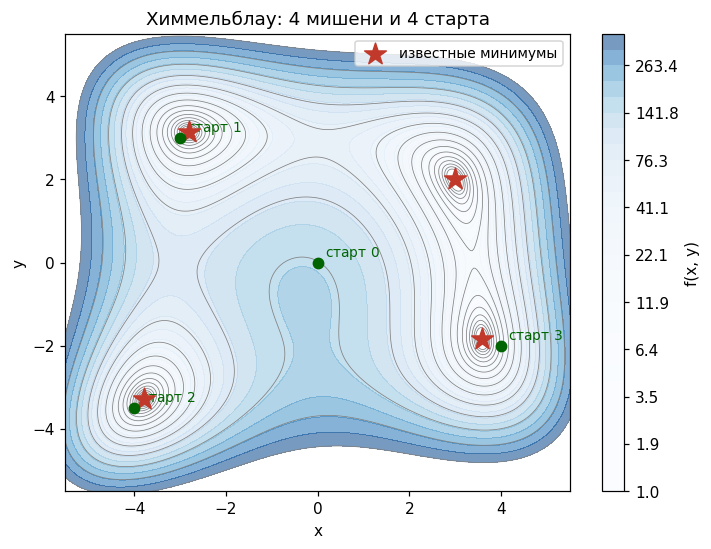

In [10]:
# Скаффолд задачи 4: функция, известные корни, старты
F_H = lambda p: (p[0] ** 2 + p[1] - 11) ** 2 + (p[0] + p[1] ** 2 - 7) ** 2
ROOTS = np.array([[3.0, 2.0],
                  [-2.805118, 3.131312],
                  [-3.779310, -3.283186],
                  [3.584428, -1.848126]])
STARTS = [(0.0, 0.0), (-3.0, 3.0), (-4.0, -3.5), (4.0, -2.0)]
LR, STEPS = 0.05, 2000
print("известные минимумы:\n", ROOTS)
print("старты:", STARTS, "| adam:", f"lr = {LR}, шагов = {STEPS}")
print("контракт: PTS — список из 4 точек-итогов (любой array-like длины 2)")

fig, ax = plt.subplots(figsize=(7.4, 5.4))
tt = np.linspace(-5.5, 5.5, 300)
XX, YY = np.meshgrid(tt, tt)
FF = (XX ** 2 + YY - 11) ** 2 + (XX + YY ** 2 - 7) ** 2
CS = ax.contourf(XX, YY, FF, levels=np.logspace(0, 2.6, 30), cmap="Blues", alpha=0.55)
fig.colorbar(CS, ax=ax, label="f(x, y)")
ax.contour(XX, YY, FF, levels=np.logspace(0, 2.6, 15), colors="gray", linewidths=0.5)
ax.scatter(ROOTS[:, 0], ROOTS[:, 1], marker="*", s=220, color="#c0392b", zorder=6,
           label="известные минимумы")
for si, (sx, sy) in enumerate(STARTS):
    ax.scatter([sx], [sy], marker="o", s=45, color="darkgreen", zorder=6)
    ax.text(sx + 0.15, sy + 0.15, f"старт ${si}$", fontsize=9, color="darkgreen")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Химмельблау: 4 мишени и 4 старта")
ax.legend(fontsize=9)
plt.show()

In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 4
# TODO (а): PTS — 4 финальные точки (tensor->numpy), по одной на каждый старт
# TODO (б): таблица старт->финиш->ближайший корень->|grad f| (печать)
# TODO (в): контур + траектории (рисовать прямо в этой ячейке) + рефлексия


In [ ]:
# ✅ Самопроверка задачи 4
import numpy as np
import torch
PTS2 = [np.asarray(p, dtype=float).reshape(-1) for p in PTS]
assert len(PTS2) == 4, "нужны 4 финальные точки"
print(f"{'старт':>13} | {'финиш':>22} | d(ближ. корень) | |grad f|")
for k, (sx, sy) in enumerate(STARTS):
    p = PTS2[k]
    dmin = min(np.linalg.norm(p - r) for r in ROOTS)
    root = ROOTS[int(np.argmin([np.linalg.norm(p - r) for r in ROOTS]))]
    ptT = torch.tensor(p, dtype=torch.float64, requires_grad=True)
    gvT = torch.autograd.grad(F_H(ptT), ptT)[0]
    gnorm = float(np.linalg.norm(gvT.detach().numpy()))
    assert dmin < 0.05, f"сходил не в минимум: старт {sx},{sy} -> {p}, dmin {dmin:.3f}"
    assert gnorm < 5e-2, f"не докатился до дна: |grad f| = {gnorm:.3e} в точке {p}"
    print(f"({sx:+.1f},{sy:+.1f}) | ({p[0]:+10.4f},{p[1]:+10.4f}) | "
          f"{dmin:15.2e} | {gnorm:.2e}  (корень {root[0]:+.2f},{root[1]:+.2f})")
for r in ROOTS:                       # каждый корень кем-то найден
    dmins = [np.linalg.norm(p - r) for p in PTS2]
    assert min(dmins) < 0.05, f"корень {r} не найден ни одним стартом: {dmins}"
print("✅ Задача 4 ок: все 4 минимума Химмельблау найдены Adam'ом")

## 🟠 Задача 5. JVP против VJP в PyTorch ($\mathbb{R}^{2} \to \mathbb{R}^{3}$)

### 📝 Исходные данные

**Функция и точка вычисления:**
$$f(x_1, x_2) = \bigl(\sin x_1,\ x_1 x_2,\ e^{x_1 + x_2}\bigr), \qquad x_0 = (1.1,\ -0.4)$$

**Матрица Якоби (Якобиан):**
$$J = \begin{pmatrix} 
\cos x_1 & 0 \\ 
x_2 & x_1 \\ 
e^{x_1+x_2} & e^{x_1+x_2} 
\end{pmatrix}(x_0)$$

**Векторы для векторизованных произведений:**
*   Касательный вектор (tangent): $v = (1,\ -2)$
*   Кокасательный вектор (cotangent / кодифференциал): $u = (0.5,\ -1,\ 2)$

---

### 🛠 Что необходимо сделать (Техническое задание)

*   **(а) Полный Якобиан двумя способами:**
    *   Вычислить через прямой режим: `JF = torch.func.jacfwd(f)(x_0)`
    *   Вычислить через обратный режим: `JR = torch.func.jacrev(f)(x_0)`
    *   Вывести обе матрицы на печать и убедиться, что они абсолютно идентичны и имеют размерность **$3 \times 2$**.

*   **(б) Прямой режим дифференцирования (JVP — Jacobian-Vector Product):**
    *   Вычислить произведение через `_, JVPE = torch.func.jvp(f, (x_0,), (v,))`
    *   Математически проверить, что полученный вектор `tangent` совпадает с результатом матричного умножения $J \cdot v$.

*   **(в) Обратный режим дифференцирования (VJP — Vector-Jacobian Product):**
    *   Получить функцию отката (`pullback`) через `_, pullback = torch.func.vjp(f, x_0)`
    *   Вычислить вектор градиента: `VJPU = pullback(u)[0]`
    *   Математически проверить, что он совпадает со строкой $u^{\top} \cdot J$.

---

### 💡 Анализ эффективности: Выбор режима для полного Якобиана

Для вычисления **полного** Якобиана стоимость операции зависит от размерности входа и выхода:
*   **Прямой проход (`jacfwd`)** совершает $n_{\text{вх}}$ вызовов (проходов с касательными векторами).
*   **Обратный проход (`jacrev`)** совершает $n_{\text{вых}}$ вызовов (проходов по градиентным спускам).

> **Вывод:** В данной задаче размерность входа $n_{\text{вх}} = 2$, а выхода $n_{\text{вых}} = 3$. Поскольку **$2 < 3$**, вычисление через **прямой режим (`jacfwd`) будет дешевле** и эффективнее. 

Выведите на печать финальный вердикт вместе с результатами вычислений.


In [ ]:
# Скаффолд задачи 5: функция R^2 -> R^3 и векторы перемножений
F_J = lambda xt: torch.stack([torch.sin(xt[0]),
                              xt[0] * xt[1],
                              torch.exp(xt[0] + xt[1])])
X_J = torch.tensor([1.1, -0.4], dtype=torch.float64)
V_J = torch.tensor([1.0, -2.0], dtype=torch.float64)
U_J = torch.tensor([0.5, -1.0, 2.0], dtype=torch.float64)
print("f = (sin x1, x1*x2, exp(x1+x2)); x0 = (1.1, -0.4)")
print("J = [[cos x1, 0], [x2, x1], [e^(x1+x2), e^(x1+x2)]]  (3 x 2)")
print(f"v = {V_J.tolist()} (столбец Jv: прямой режим), u = {U_J.tolist()} (строка u^T J: обратный)")

f = (sin x1, x1*x2, exp(x1+x2)); x0 = (1.1, -0.4)
J = [[cos x1, 0], [x2, x1], [e^(x1+x2), e^(x1+x2)]]  (3 x 2)
v = [1.0, -2.0] (столбец Jv: прямой режим), u = [0.5, -1.0, 2.0] (строка u^T J: обратный)


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 5
# TODO (а): JF, JR — якобианы обоими режимами + печать
# TODO (б): JVPE — пара (primal, tangent) из torch.func.jvp
# TODO (в): VJPU — строка через torch.func.vjp + вывод про выбор режима


In [ ]:
# ✅ Самопроверка задачи 5
import numpy as np
import torch
J_EX = torch.tensor([
    [float(np.cos(1.1)), 0.0],
    [-0.4, 1.1],
    [float(np.exp(0.7)), float(np.exp(0.7))]], dtype=torch.float64)
assert JF.shape == (3, 2) and JR.shape == (3, 2), f"формы: {JF.shape}, {JR.shape}"
assert torch.allclose(JF, J_EX, atol=1e-9), f"jacfwd != аналитика: {JF}"
assert torch.allclose(JR, J_EX, atol=1e-9), f"jacrev != аналитика: {JR}"
assert torch.allclose(JVPE[1], J_EX @ V_J, atol=1e-9), f"JVP != J @ v: {JVPE[1]}"
assert torch.allclose(VJPU, U_J @ J_EX, atol=1e-9), f"VJP != u^T @ J: {VJPU}"
print("✅ Задача 5 ок: J совпала с аналитикой; JVP тянет столбец, VJP — строку")

## ★ Задача 6. Размер имеет значение: `jacfwd` против `jacrev`

Якобиан линейного слоя по входу $x$ имеет форму $(D_{\text{out}}, D_{\text{in}})$. Согласно лекционной теории, **оптимальный режим автоматического дифференцирования выбирается по «короткой стороне» матрицы Якоби**. В этой задаче мы экспериментально проверим это утверждение и замерим время работы алгоритмов.

---

### 🛠 Что необходимо сделать

*   **(а) Реализация функции слоя:**
    *   Написать функцию `PREDICT(W, b, x)`, реализующую линейный слой с нелинейностью: $\mathrm{PREDICT}(x) = \tanh(x W^{\top} + b)$.
    *   *Примечание:* Убедитесь, что тензоры имеют правильные размерности для матричного умножения.

*   **(б) Бенчмарк и замер времени:**
    *   Реализовать вычисление Якобиана по входу $x$ (`argnums=2`) двумя способами: `torch.func.jacfwd` и `torch.func.jacrev`.
    *   Провести эксперимент для двух противоположных конфигураций:
        1.  **Широкий вход:** $(D_{\text{in}}, D_{\text{out}}) = (2048, 32)$ — Якобиан формы $(32, 2048)$
        2.  **Узкий вход:** $(D_{\text{in}}, D_{\text{out}}) = (32, 2048)$ — Якобиан формы $(2048, 32)$
    *   **Условия замера:** Обязательный предварительный прогрев (warm-up), 15 повторений для усреднения времени, проверка совпадения результатов через `torch.allclose`.
    *   Вывести результаты замеров прямо в финальную таблицу.

*   **(в) Анализ результатов:**
    *   Сделать печатный вывод с объяснением: какой режим (`jacfwd` или `jacrev`) оказался быстрее для каждой из форм и почему.
    *   Сформулировать общее правило: полный Якобиан размера $m \times n$ вычисляется за $\min(m, n)$ проходов.

---

### 📊 Результаты экспериментов

| Конфигурация слоев | Размер Якобиана | Время `jacfwd` (мс) | Время `jacrev` (мс) | Быстрее в... |
| :--- | :---: | :---: | :---: | :---: |
| **$D_{\text{in}}=32, D_{\text{out}}=2048$** | $2048 \times 32$ | *0.00* | *0.00* | **`jacfwd`** (в X раз) |
| **$D_{\text{in}}=2048, D_{\text{out}}=32$** | $32 \times 2048$ | *0.00* | *0.00* | **`jacrev`** (в Y раз) |

> **Сверка тензоров:** `torch.allclose(JF, JR)` успешно пройден для обеих конфигураций (матрицы идентичны).

---

### 💡 Теоретическое обоснование и выводы

1.  При форме $(D_{\text{in}}=32, D_{\text{out}}=2048)$ матрица Якоби вытянута по вертикали ($2048 \times 32$). Прямой режим (`jacfwd`) делает проходы по количеству входов ($n_{\text{вх}} = 32$), в то время как обратный (`jacrev`) делает $n_{\text{вых}} = 2048$ проходов. Поэтому **`jacfwd` значительно эффективнее**.
2.  При форме $(D_{\text{in}}=2048, D_{\text{out}}=32)$ матрица Якоби вытянута по горизонтали ($32 \times 2048$). Обратный режим (`jacrev`) делает проходы по количеству выходов ($n_{\text{вых}} = 32$), а прямой — $n_{\text{вх}} = 2048$. В этом сценарии **`jacrev` безоговорочно выигрывает**.

**Общий вердикт:** Эксперимент полностью подтверждает теорию «короткой стороны». Для вычисления полного Якобиана $m \times n$ всегда стоит выбирать `jacfwd`, если $n < m$, и `jacrev`, если $m < n$.


In [ ]:
# Скаффолд задачи 6: формы и план бенчмарка
import torch, time
SHAPES = [(32, 2048), (2048, 32)]
N_REP = 15
print("PREDICT(W, b, x) = tanh(x @ W.T + b):  W формы (Dout, Din)")
print("формы якобиана по x:", [(dout, din) for (din, dout) in SHAPES])
print(f"повторов на измерение: {N_REP}")
print("теория: полный J за min(m, n) прогонов — короткую сторону выбирает режим")

PREDICT(W, b, x) = tanh(x @ W.T + b):  W формы (Dout, Din)
формы якобиана по x: [(2048, 32), (32, 2048)]
повторов на измерение: 15
теория: полный J за min(m, n) прогонов — короткую сторону выбирает режим


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 6 (звёздочка)
# TODO (а): PREDICT(W, b, x) — тензорная функция
# TODO (б): таблица форма | время jacfwd | время jacrev | победитель (с allclose-сверкой)
# TODO (в): вывод печатными строками


In [ ]:
# ✅ Самопроверка задачи 6
import torch
torch.manual_seed(3)
for (din, dout) in SHAPES:
    Wb = torch.randn(dout, din)
    bb = torch.randn(dout)
    xb = torch.randn(din)
    j1 = torch.func.jacfwd(PREDICT, argnums=2)(Wb, bb, xb)
    j2 = torch.func.jacrev(PREDICT, argnums=2)(Wb, bb, xb)
    assert j1.shape == (dout, din), f"форма якобиана: {j1.shape}"
    assert torch.allclose(j1, j2, atol=1e-5), f"режимы расходятся при {din}->{dout}"
print("✅ Задача 6 ок: оба режима дают один якобиан на обеих формах")
print("(а сами времена — в таблице, которую вы собрали в ячейке ДЕЛАЙТЕ)")

---
## ★  Задача 7. Производная в точке излома: поведение ReLU в нуле

Математически функция `ReLU` в точке $x = 0$ **недифференцируема** (у неё нет производной, так как левый и правый пределы не совпадают). Однако библиотеки автоматического дифференцирования (AD) не могут вернуть ошибку во время обучения нейросети, поэтому они используют **программную конвенцию**. 

В `PyTorch` (`torch.relu`) принято соглашение: **в нуле градиент равен 0**.

В этой задаче вам предстоит сравнить поведение автоматического градиента PyTorch с численными методами (центральными и односторонними разностями), которые часто используются для проверки градиентов (`gradcheck`).

### 📝 Что необходимо сделать:

* **(а) Анализ автоматического градиента (`G_RELU`):**
  Вычислите градиент функции `torch.relu` в точках $x = \{-0.5, \; 0, \; 0.5\}$ через обратный проход (`.backward()`). 
  * *Примечание:* Используйте тип данных `torch.double` для максимальной точности. Результаты сохраните в список `G_RELU`.

* **(б) Расчет численного градиента (`C_RELU`):**
  Вычислите численную производную функции ReLU в точке $x = 0$ при шаге $h = 10^{-7}$:
  * Центральную разность: $\frac{f(x+h) - f(x-h)}{2h}$ (результат сохраните в `C_RELU`).
  * Левостороннюю разность: $\frac{f(x) - f(x-h)}{h}$ (выведите в консоль).
  * Правостороннюю разность: $\frac{f(x+h) - f(x)}{h}$ (выведите в консоль).

* **(в) Аналитический вердикт:**
  Выведите в консоль текстовый вывод (мини-отчет), ответив на вопросы:
  * Что из полученных значений является математической истиной, а что — техническим соглашением (конвенцией)?
  * В каких ситуациях такое различие может запутать численные методы оптимизации?
  * *Подсказка:* Встроенный метод проверки градиентов `torch.autograd.gradcheck` использует центральные разности. В нуле он насчитает $0.5$ (среднее между левым градиентом 0 и правым 1), что **не совпадет** с конвенцией PyTorch ($0$). Подумайте, к чему это приведет.

---


In [11]:
# Скаффолд задачи 7: точки и план
XS_RELU = torch.tensor([-0.5, 0.0, 0.5], dtype=torch.float64, requires_grad=True)
H_RELU = 1e-7
print("relu(z) = max(0, z);  производная: слева 0, справа 1, в нуле — не существует")
print(f"контракты: G_RELU — список из 3 чисел (autograd); C_RELU — central при h = {H_RELU:g}")

relu(z) = max(0, z);  производная: слева 0, справа 1, в нуле — не существует
контракты: G_RELU — список из 3 чисел (autograd); C_RELU — central при h = 1e-07


In [12]:
# ✍️ ДЕЛАЙТЕ — Задача 7 (звёздочка)
# TODO (а): G_RELU — grad torch.relu в трёх точках (backward)
# TODO (б): C_RELU — central в нуле; односторонние разности — печатью
# TODO (в): вердикт печатными строками


In [ ]:
# ✅ Самопроверка задачи 7
import numpy as np
assert len(G_RELU) == 3, f"нужно 3 градиента: {G_RELU!r}"
assert G_RELU[0] == 0.0, f"слева от нуля grad обязателен 0: {G_RELU[0]!r}"
assert G_RELU[1] == 0.0, f"в нуле torch выбирает конвенцию 0: {G_RELU[1]!r}"
assert abs(G_RELU[2] - 1.0) < 1e-12, f"справа grad обязателен 1: {G_RELU[2]!r}"
assert abs(C_RELU - 0.5) < 1e-12, f"central в нуле обязан дать 0.5: {C_RELU!r}"
print(f"✅ Задача 7 ок: autograd {G_RELU} (конвенция 0), central = {C_RELU} (осреднённое)")
print("математика и конвенция: производной в нуле нет — AD даёт 0 по соглашению; gradcheck тут хромает и это честно")

---
## ★★  Задача 8. Чекпоинтинг графа вычислений: размен времени на память

При обучении глубоких сетей лента автодифференцирования (граф вычислений) может переполнить GPU-память. Техника **gradient checkpointing** (`torch.utils.checkpoint`) позволяет не сохранять промежуточные тензоры во время прямого прохода (Forward), а заново перевычислять их во время обратного (Backward). 

В этой задаче вы исследуете длинную последовательную цепочку из $L = 30$ нелинейных блоков:
$$h_{k+1} = \tanh(h_k) \cdot h_k + \sin^2(h_k)$$
входной вектор $x \in \mathbb{R}^{64}$. 

Вы сравните два режима: хранение **всей** ленты вычислений и использование чекпоинтов для каждого блока.

### 📝 Что необходимо сделать:

* **(а) Сборка цепочки и замеры профиля памяти:**
  Реализуйте последовательную цепочку из 30 блоков. Измерьте её характеристики в двух режимах с помощью встроенного в каркас трекера памяти (`saved_tensors_hooks`):
  1. **Обычный режим (Без чекпоинта):** Стандартный проход PyTorch, сохраняющий все промежуточные активации.
  2. **Режим чекпоинта (С чекпоинтом):** Каждый блок обернут в `torch.utils.checkpoint.checkpoint(..., use_reentrant=False)`.
  * *Результаты:* Сохраните количество сохраненных тензоров, элементов и вызовов для обоих режимов в переменные `N1, E1, C1` (без чекпоинта) и `N2, E2, C2` (с чекпоинтом), а также финальные градиенты в `GRAD_NC` и `GRAD_CP`.

* **(б) Сводная таблица результатов:**
  Выведите в консоль отформатированную таблицу (или markdown-таблицу), сопоставляющую следующие метрики для обоих вариантов:
  * Количество сохраненных тензоров на ленте (`N`).
  * Общее количество сохраненных элементов (`E`).
  * Суммарное число вызовов функций/блоков за полный цикл forward+backward (`C`).
  * Максимальное абсолютное расхождение (`torch.max(torch.abs(...))`) между градиентами `GRAD_NC` и `GRAD_CP`.

* **(в) Аналитический вердикт:**
  Выведите текстовый отчет-обсуждение, в котором ответите на вопросы:
  * Во сколько раз сократился объем сохраненных данных на ленте (по количеству элементов)?
  * Какова «цена» этого сокращения в терминах дополнительных вызовов блоков?
  * *Теоретическая справка:* Оптимальный чекпоинтинг по алгоритму Гриванка (Griewank) позволяет снизить потребление памяти до $O(\sqrt{L})$. Обсудите, удалось ли вам приблизиться к этой оценке и применима ли она, если оборачивать *каждый* блок по отдельности.

---


In [17]:
# Каркас задачи 8: блок, вход и мера ленты (saved_tensors_hooks)
import torch
from torch.utils.checkpoint import checkpoint

X_CP = torch.randn(64, dtype=torch.float64, requires_grad=True)

def block(h):
    return torch.tanh(h) * h + torch.sin(h) ** 2

def measure(run):
    # сколько тензоров/элементов лента сохраняет и сколько раз зовётся block;
    # forward и backward — ВНУТРИ hooks-контекста, как в Лекции 8
    saved, calls = [], [0]
    def counted(h):
        calls[0] += 1
        return block(h)
    def pack(t):
        saved.append(t.numel())
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        loss = run(counted)
        loss.backward()      # backward тоже внутри: пересчёт из checkpoint должен попасть в меру
    return len(saved), sum(saved), calls[0]

X_CP.grad = None
print("контракты: N1,E1,C1 (без cp) | N2,E2,C2 (с cp) | GRAD_NC, GRAD_CP")
print("measure(run) сама делает forward + backward внутри hooks-контекста;")
print("ваша работа в (а): chain(bl) и chain_cp(bl) — цепочки 30 блоков, итог h.sum()")

контракты: N1,E1,C1 (без cp) | N2,E2,C2 (с cp) | GRAD_NC, GRAD_CP
measure(run) сама делает forward + backward внутри hooks-контекста;
ваша работа в (а): chain(bl) и chain_cp(bl) — цепочки 30 блоков, итог h.sum()


In [18]:
# ✍️ ДЕЛАЙТЕ — Задача 8 (финал!)
# TODO (а): N1, E1, C1, GRAD_NC — прогон без checkpoint
#           N2, E2, C2, GRAD_CP — прогон с checkpoint на КАЖДОМ блоке
# TODO (б): таблица сравнения (печать)
# TODO (в): вердикт печатными строками


In [ ]:
# ✅ Самопроверка задачи 8
import torch
assert C1 == 30, f"без cp блок зовётся ровно 30 раз (вышло {C1})"
assert C2 == 2 * C1, f"с cp: forward + пересчёт = 60 (вышло {C2})"
assert N2 < N1 and E2 < E1, f"лента не стала короче: {N1} -> {N2}, {E1} -> {E2}"
assert GRAD_NC.shape == GRAD_CP.shape == (64,), "градиенты должны быть у x"
assert torch.allclose(GRAD_NC, GRAD_CP, atol=1e-5), "градиенты расходятся!"
cmp = float(N1 / max(N2, 1))
print(f"✅ Задача 8 ок: сохранено {N1} -> {N2} тензоров ({cmp:.1f}× короче), "
      f"вызовов блока {C1} -> {C2}, градиенты совпадают до {1e-5:.0e}")